# Prédiction du risques pour la santé maternelle grâce à l'IA

## 1. Importation des bibliothèques nécessaires

In [2]:
# Pour eviter tous messages d'erreurs liés aux environnements de python il est 
# recommandé d'importer le package qui permet de les gérer en première position

# Erreurs
import warnings
warnings.filterwarnings('ignore')

# Manipulation et analyses des données
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning - Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Regression Logistique et Random Forest
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


# Machine Learning - Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, classification_report, confusion_matrix,
    roc_auc_score
)
# Fixer des graines aléatoires pour la reproductibilité
np.random.seed(42)

## 2. Préparation de la données
### 2.1 Importation de la dataset

In [3]:
df= pd.read_csv("Maternal_Health_Risk_Data_Set.csv")

### 2.2 Initial data exploration

In [4]:
print(f"Le jeu de donées comporte {df.shape[0]} patientes et {df.shape[1]-1} variables explicatives.")

Le jeu de donées comporte 1014 patientes et 6 variables explicatives.


In [5]:
# Affichage de la dataset
df.head()
print(f"\nLes 5 premières lignes du jeu de donnees:\n{df.head()}")
# Affichage de la statistique descriptive.
print(f"\n La statistique descriptive de notre jeu de donnees se présente comme suit: \n{df.describe()}")


Les 5 premières lignes du jeu de donnees:
   Age  SystolicBP  DiastolicBP    BS  BodyTemp  HeartRate  RiskLevel
0   25       130.0         80.0  15.0      98.0       86.0  high risk
1   35       140.0         90.0  13.0      98.0       70.0  high risk
2   29        90.0         70.0   8.0     100.0       80.0  high risk
3   30       140.0         85.0   7.0      98.0       70.0  high risk
4   35       120.0         60.0   6.1      98.0       76.0   low risk

 La statistique descriptive de notre jeu de donnees se présente comme suit: 
               Age   SystolicBP  DiastolicBP           BS     BodyTemp  \
count  1014.000000  1011.000000  1013.000000  1014.000000  1014.000000   
mean     29.871795   113.207715    76.461994     8.725986    98.665089   
std      13.474386    18.414275    13.892579     3.293532     1.371384   
min      10.000000    70.000000    49.000000     6.000000    98.000000   
25%      19.000000   100.000000    65.000000     6.900000    98.000000   
50%      26.000

### 2.3 Recherche des doublons et correction

In [6]:
df.duplicated().sum()

np.int64(550)

In [7]:
df.drop_duplicates()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130.0,80.0,15.00,98.0,86.0,high risk
1,35,140.0,90.0,13.00,98.0,70.0,high risk
2,29,90.0,70.0,8.00,100.0,80.0,high risk
3,30,140.0,85.0,7.00,98.0,70.0,high risk
4,35,120.0,60.0,6.10,98.0,76.0,low risk
...,...,...,...,...,...,...,...
680,42,130.0,80.0,18.00,98.0,70.0,high risk
703,15,100.0,49.0,7.60,98.0,77.0,low risk
704,12,100.0,50.0,6.00,98.0,70.0,mid risk
705,21,100.0,50.0,6.80,98.0,60.0,low risk


### 2.4 Recherche des valeurs manquantes

In [8]:
# Affichage des données manquantes
df.isnull().sum()
print(f"\n Les données manquantes par chaque variable est: {df.isnull().sum()}")


 Les données manquantes par chaque variable est: Age            0
SystolicBP     3
DiastolicBP    1
BS             0
BodyTemp       0
HeartRate      1
RiskLevel      0
dtype: int64


### 2.5 Exploration de la distribution des variables

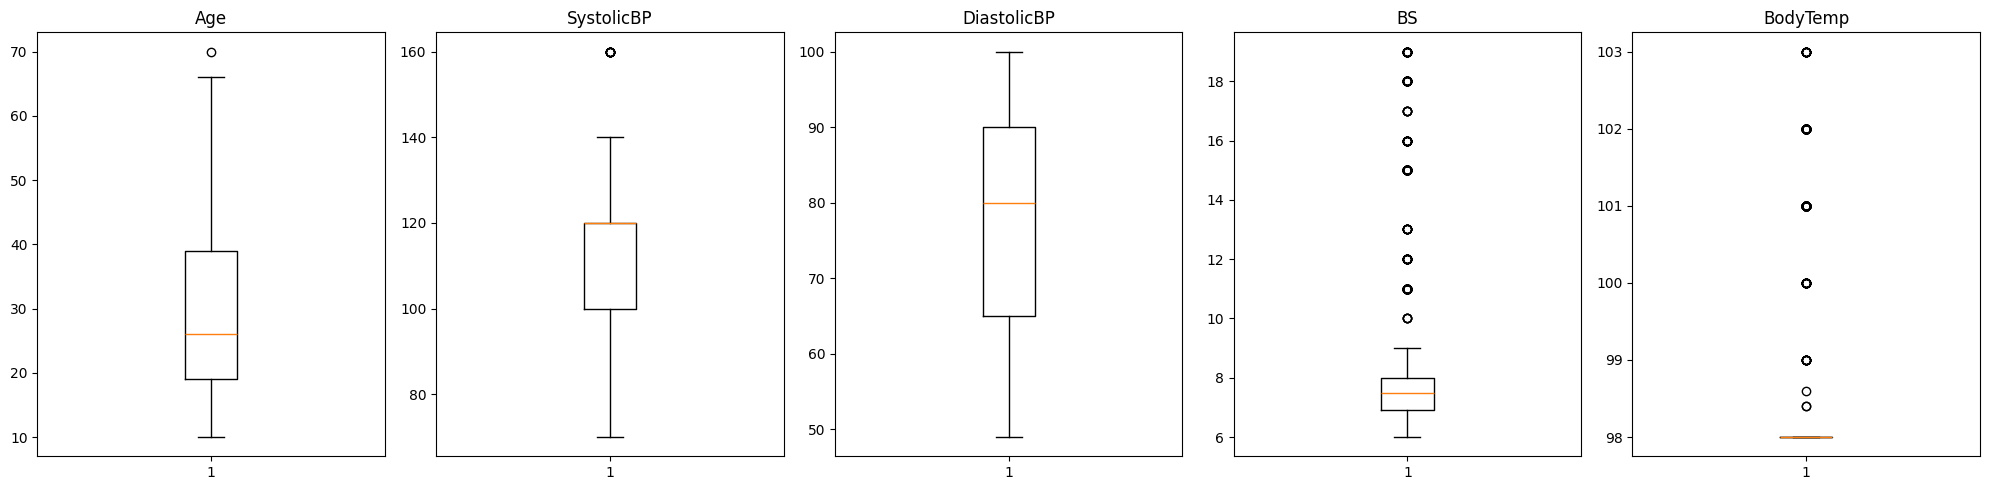

In [9]:
# Sélectionner uniquement les 5 premières colonnes numériques (pour éviter l'IndexError)
colonnes_numeriques = df.select_dtypes(include=['number']).columns[:5]

# Créer une figure avec 1 ligne et 5 colonnes de graphiques
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i, col in enumerate(colonnes_numeriques):
    axes[i].boxplot(df[col].dropna())
    axes[i].set_title(col)
plt.tight_layout()  # Aligne proprement et évite les chevauchements
plt.show()

#### INTERPRETATION
La représentation graphique des variables quantitatives du dataset met en évidence la présence de valeurs aberrantes (outliers). Ce phénomène est particulièrement marqué pour les variables BS et BodyTemp, où plusieurs observations se situent nettement au-dessus de la moustache supérieure. Fort de ce constat, je propose de remplacer les valeurs manquantes par la médiane, car elle est plus robuste que la moyenne dans ce cas de figure.

### 2.6 Imputation des valeurs manquantes par mediane

In [10]:
for col in df.columns:
    if df[col].isna().sum() !=0:
        df[col]=df[col].fillna(df[col].median())

### 2.7 Observation de la distribution de la variable dépendante

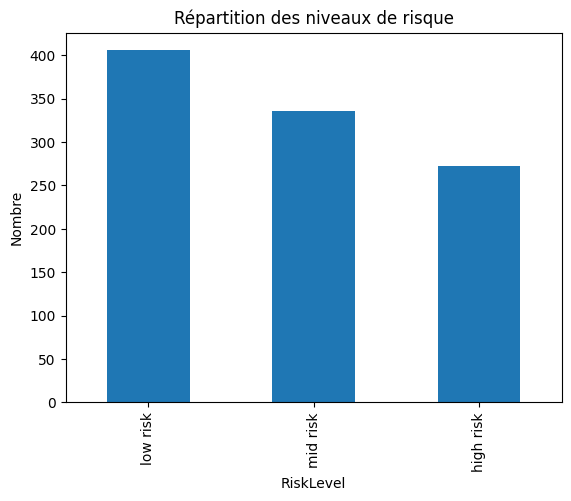

In [11]:
df["RiskLevel"]=df["RiskLevel"].str.lower()# Pour uniformiser les modalités de la variable
df['RiskLevel'].value_counts().plot(kind="bar")
plt.xlabel("RiskLevel")
plt.ylabel("Nombre")
plt.title("Répartition des niveaux de risque")
plt.show()

### 2.8: Normalisation des données (pour mieux visualiser)

In [12]:
# Create a normalized copy for visualization
dat= df.copy()# Pour conserver le jeu de données de départ apurée et non normalisé
# Create a StandardScaler object to standardize features
scaler = StandardScaler()
features = df.drop(columns=["RiskLevel"])
features_transform = scaler.fit_transform(features)# Les varaiables explicatives 

**N.B:** En normalisant toute la dataset, nous comettons une erreur classique en Data Science
appelée la fuite de données (Data Leakage).

## 3.Évaluation du risque des patients - Modèle de Regression Logistique
### 3.1 Préparer les données pour la modélisation

In [13]:
# Encodage de la target
encoder = LabelEncoder()
df["RiskLevel_encoder"] = encoder.fit_transform(df["RiskLevel"])

### 3.2 Séparation Train-Test 

In [14]:
# Train-Test split with stratification
target= df['RiskLevel']
X_train, X_test, y_train, y_test = train_test_split(
                                                    features, target,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=df.RiskLevel_encoder
                                                    )

# 1. Print number of samples
print("Number of training samples:", X_train.shape[0])
print("Number of test samples:", X_test.shape[0])

# 2. Optional: Check number of features
print("Number of features:", X_train.shape[1])

# 3. Check class distribution in train/test sets
print("\nTraining set class distribution:\n", y_train.value_counts())
print("\nTest set class distribution:\n", y_test.value_counts())

Number of training samples: 811
Number of test samples: 203
Number of features: 6

Training set class distribution:
 RiskLevel
low risk     325
mid risk     269
high risk    217
Name: count, dtype: int64

Test set class distribution:
 RiskLevel
low risk     81
mid risk     67
high risk    55
Name: count, dtype: int64


In [15]:
# Séparer la cible (target) et les variables explicatives (features)
target = df["RiskLevel_encoder"]
features = df.drop(columns=["RiskLevel", "RiskLevel_encoder"])

In [16]:
print(encoder.classes_) #  0: 'high risk', 1:'low risk', 2:'mid risk'

['high risk' 'low risk' 'mid risk']


### 3.3 Normalisation des données

In [17]:
scaler= StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 3.4 ENTRAINEMENT DU MODELE DE REGRESSION LOGISTIQUE AVEC SKLEARN

In [18]:
model= LogisticRegression(multi_class='multinomial', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'multinomial'


In [19]:
y_pred=model.predict(X_test_scaled)
print(f"Precision globale (Accuracy): {accuracy_score(y_test,y_pred):.2%}\n")
print("Rapport de classification:")
print(classification_report(y_test, y_pred, target_names=["Low Risk", "Mid Risk","High Risk"]))

Precision globale (Accuracy): 62.07%

Rapport de classification:
              precision    recall  f1-score   support

    Low Risk       0.78      0.78      0.78        55
    Mid Risk       0.59      0.77      0.67        81
   High Risk       0.49      0.31      0.38        67

    accuracy                           0.62       203
   macro avg       0.62      0.62      0.61       203
weighted avg       0.61      0.62      0.60       203



### 3.5: ENTRAINEMENT DU MODELE DE REGRESSION LOGISTIQUE AVEC STATMODELS

In [20]:
Train= features
Train_test= scaler.fit_transform(Train)
Target= df["RiskLevel_encoder"]           

In [21]:
data_train= pd.DataFrame(Train_test, columns= Train.columns)
data_train["RiskLevel_encoder"]= Target.values

In [22]:
import statsmodels.formula.api as smf
formule = "RiskLevel_encoder ~ " + " + ".join(Train.columns)
modele_smf = smf.mnlogit(formula=formule, data=data_train).fit()
print(modele_smf.summary())

Optimization terminated successfully.
         Current function value: 0.770840
         Iterations 8
                          MNLogit Regression Results                          
Dep. Variable:      RiskLevel_encoder   No. Observations:                 1014
Model:                        MNLogit   Df Residuals:                     1000
Method:                           MLE   Df Model:                           12
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                  0.2898
Time:                        09:30:33   Log-Likelihood:                -781.63
converged:                       True   LL-Null:                       -1100.7
Covariance Type:            nonrobust   LLR p-value:                7.885e-129
RiskLevel_encoder=1       coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.4222      0.153      2.763      0.006       0.123       0.722
Ag

### INTERPRETATION DU MODELE DE REGRESSION LOGISTIQUE

**pseudo R^{2}**
Le pseudo R^{2} observé est environ de 30 % signifie ce qui veut dire que le modèle explique 30 % de la déviance (ou de la variabilité) du modèle nul (le modèle sans aucune variable explicative). Il mesure l'amélioration de la prédiction grâce à vos variables.

**Variables explicatives**

Les variables SystolicBP (Pression systolique), BS (Glycémie), BodyTemp (Température) et HeartRate (Fréquence cardiaque) sont hautement significatives pour expliquer la différence entre un risque Faible et un risque Élevé (leurs p-values P>|z| sont égales à 0.000, soit bien inférieures au seuil de 5 %).
L'âge (p = 0.078) et la pression diastolique (p = 0.099) ne sont pas significatifs à ce seuil.

**RiskLevel_encoder=1**

Toutes choses étant égales par ailleurs, une augmentation d'une unité de la pression artérielle systolique (SystolicBP) entraîne une diminution de 1.2052 du logarithme du ratio des chances (log-odds) d'être classé en risque Faible (Low) plutôt qu'en risque Élevé (High).
En termes de risques relatifs (e^{-1.2052} ce qui correspond approximativement à  0.30, cela signifie qu'à chaque unité supplémentaire de pression systolique, les chances qu'un patient se trouve dans la catégorie de risque Faible (par rapport à la référence de risque Élevé) diminuent de 70 % (1 - 0.30).

## 4. BONUS RANDOM FOREST

### 4.1 Entrainement du modèle de random Forest

In [38]:
# Initialize and train Random Forest Classifier
model_rf = RandomForestClassifier(
    n_estimators=50,      # number of trees
    max_depth=None,        # let trees expand fully unless limited
    random_state=42,       # for reproducibility
    n_jobs=-1              # use all processors
)

model_rf.fit(X_train_scaled, y_train)

,n_estimators,50
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### 4.2 EVALUATION DU MODELE DE RANDOM FOREST

In [48]:
y_pred_rf = model_rf.predict(X_test_scaled)
print(f"Precision globale (Accuracy): {accuracy_score(y_test, y_pred_rf):.2%}\n")
print("Rapport de classification :")
print(classification_report(y_test, y_pred_rf, target_names=["Low Risk", "Mid Risk", "High Risk"]))

Precision globale (Accuracy): 86.70%

Rapport de classification :
              precision    recall  f1-score   support

    Low Risk       0.96      0.95      0.95        55
    Mid Risk       0.90      0.80      0.85        81
   High Risk       0.77      0.88      0.82        67

    accuracy                           0.87       203
   macro avg       0.88      0.88      0.87       203
weighted avg       0.87      0.87      0.87       203



#### INTERPRETATION DES RESULTATS

**Le modèle Random Forest** présente d'excellentes performances globales avec une précision (Accuracy) de 87 % sur le jeu de test. 
Contrairement au modèle logistique, la forêt aléatoire parvient à capturer efficacement la complexité et les relations non linéaires des variables cliniques (Age, BS, SystolicBP, DiastolicBP etc.).

**L'analyse détaillée par classe de risque révèle une grande robustesse:**

**• Classe Low Risk (Risque Faible)** : Le modèle obtient un F1-score remarquable de 0,95, soutenu par une précision de 96 % et un rappel de 95 %. Les patientes à faible risque sont presque parfaitement identifiées.

**• Classe High Risk (Risque Élevé):** C'est l'amélioration la plus critique d'un point de vue médical. Le rappel (sensibilité) atteint 88 %. Cela signifie que le modèle identifie et sécurise 88 % des patientes réellement en danger, limitant drastiquement le risque médical lié aux faux négatifs (patientes graves non détectées).

**• Classe Mid Risk (Risque Modéré):** Le modèle maintient une bonne performance générale avec un F1-score de 0,85.

**En conclusion**, le Random Forest se montre particulièrement adapté à ce jeu de données de santé maternelle. Sa structure en arbres de décision lui permet de détecter nativement les effets de seuil cliniques et les interactions complexes entre les constantes vitales des patientes.
